In [1]:
import numpy as np
import matplotlib.pyplot as plt
import torch

from model import ExponentialRepresentation
from utils import plot_ratemaps, rectify, construct_exponential, batch_inference, orthogonal_basis

In [2]:
# init R 
# R is a basis for the plane sum_i p_i = 0

In [3]:
sA = torch.load("sigma_A.pt", weights_only=True) # Must run fourier_approximation.ipynb first now!
sB = torch.load("sigma_B.pt", weights_only=True)

A, B, _ = construct_exponential(sA, sB, sB*0, s = 0) 

N = len(A)

In [4]:
one_vec = np.ones(N + 1)/np.sqrt(N + 1)

# Perform Gram-Schmidt starting from the ones vector, which is orthogonal to zero-sum plane
# R^TR is the projection matrix onto the plane orthogonal to 1
R = torch.tensor(orthogonal_basis(one_vec).astype("float32"))
R = R[1:] # remove ones vector from basis!
R.shape

torch.Size([256, 257])

In [5]:
# p0 should be in the zero-sum plane - 

# Rp0 = \pm 1 
# R^TR p0 = \pm R^T 1 
# P p0 = \pm R^T 1
# if p0 is in plane, P p0 = p0
# p0 = \pm R^T 1
 
# works if \pm 1 is in plane. (cause R^T x is still in plane if x is), i.e. 1^T (R^Tx) = (R1)^T x  = 0 

signs = torch.tensor([(-1)**i for i in range(N)]).float()

p0 = R.T@signs 
p0 = p0/torch.linalg.norm(p0)
p0.shape

torch.Size([257])

In [6]:
model = ExponentialRepresentation(R.T@A@R, R.T@B@R)

/home/m/Documents/phd/ESR/model.py:20: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.A = torch.tensor(A, device=self.device, requires_grad=False)
/home/m/Documents/phd/ESR/model.py:21: UserWarning: To copy construct from a tensor, it is recommended to use sourceTensor.clone().detach() or sourceTensor.clone().detach().requires_grad_(True), rather than torch.tensor(sourceTensor).
  self.B = torch.tensor(B, device=self.device, requires_grad=False)


In [7]:
batch_size = 50 # number of spatial samples
batches = 500
arena_size = 10
r_batch = [arena_size*(2*torch.rand((batch_size, 2)).to(torch.float32) - 1) for i in range(batches)]

p = batch_inference(model, r_batch, p0)
z = p + np.ones((1, N+1)) # avoid numerical issues
r = np.concatenate(r_batch)

  0%|          | 0/500 [00:00<?, ?it/s]

100%|██████████| 500/500 [00:06<00:00, 79.98it/s]


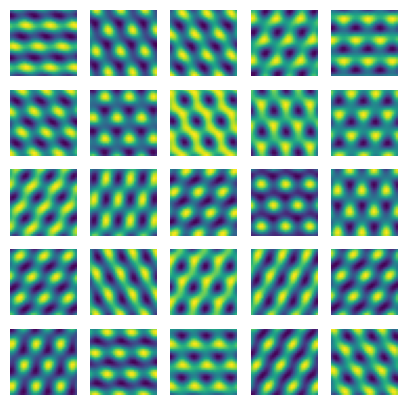

In [8]:
ratemaps = plot_ratemaps(r[:,0], r[:,1], z, 5, figsize=(5,5), bins = 32)

In [9]:
norm = np.linalg.norm(ratemaps, axis=0)
rate_sum = np.sum(ratemaps, axis=0)

Text(0.5, 1.0, 'Histogram of (shifted) rates')

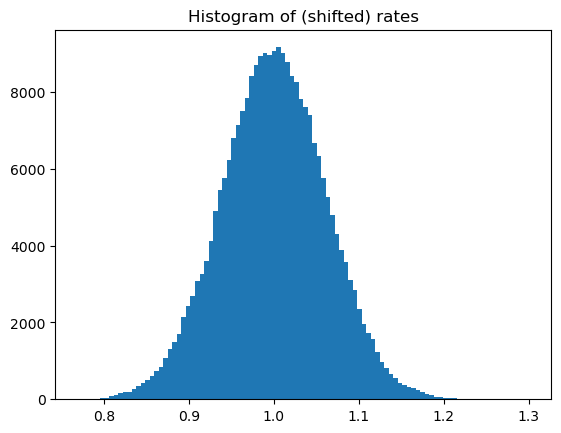

In [10]:
plt.hist(ratemaps.ravel(), bins = 100)
plt.title("Histogram of (shifted) rates")

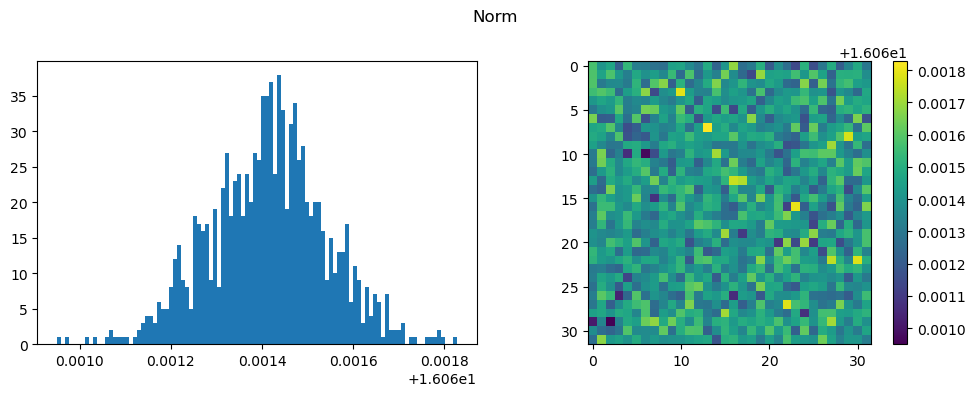

In [11]:
fig, ax = plt.subplots(1, 2, figsize = (10, 4))

ax[0].hist(norm.ravel(), bins = 100)
im = ax[1].imshow(norm)
fig.suptitle("Norm")
plt.colorbar(im, ax = ax[1] )
plt.tight_layout()

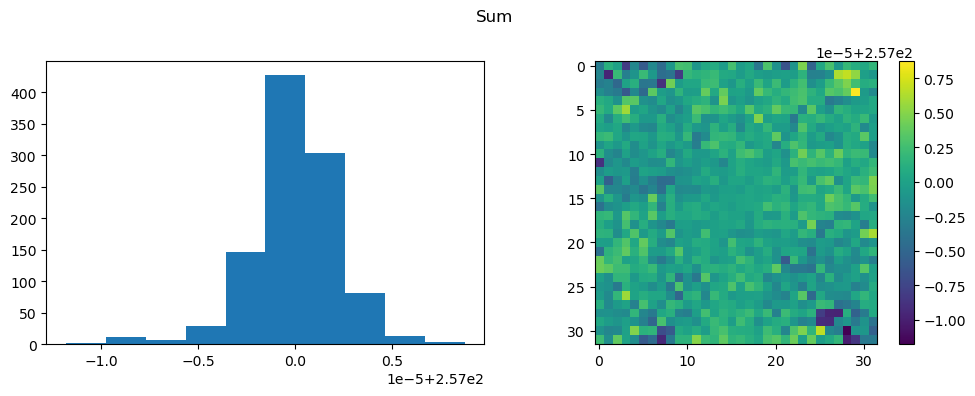

In [12]:
fig, ax = plt.subplots(1, 2, figsize = (10, 4))

ax[0].hist(rate_sum.ravel(), bins = 10)

im = ax[1].imshow(rate_sum)
fig.suptitle("Sum")
plt.colorbar(im, ax = ax[1])
plt.tight_layout()

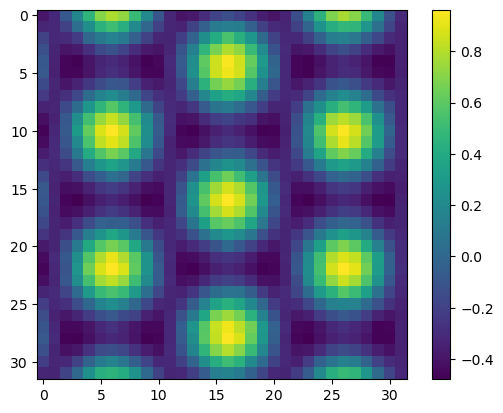

In [13]:
a = 16
corr = np.sum(ratemaps[:, a, a, None, None]*ratemaps, axis = 0)
plt.imshow(corr.T - (N + 1))
plt.colorbar()

In [14]:
M = 2000
x = np.random.normal(0, 1, (256, M))
xhat = x/np.linalg.norm(x, axis=-1, keepdims = True)
xhat += np.ones((1, M))
xhat.shape

corrs = np.sum(xhat[None]*xhat[:,None], axis = -1)

(array([2.000e+00, 2.000e+00, 0.000e+00, 6.000e+00, 0.000e+00, 5.000e+00,
        6.000e+00, 1.000e+01, 1.000e+01, 1.500e+01, 2.600e+01, 2.000e+01,
        4.300e+01, 5.800e+01, 7.200e+01, 8.000e+01, 9.900e+01, 1.390e+02,
        1.540e+02, 1.900e+02, 2.320e+02, 2.870e+02, 3.170e+02, 4.440e+02,
        5.030e+02, 5.920e+02, 6.580e+02, 8.050e+02, 1.012e+03, 1.137e+03,
        1.260e+03, 1.437e+03, 1.630e+03, 1.708e+03, 2.097e+03, 2.259e+03,
        2.339e+03, 2.301e+03, 2.451e+03, 2.606e+03, 2.780e+03, 2.746e+03,
        2.655e+03, 2.599e+03, 2.562e+03, 2.574e+03, 2.483e+03, 2.277e+03,
        2.135e+03, 1.905e+03, 1.827e+03, 1.683e+03, 1.539e+03, 1.309e+03,
        1.194e+03, 1.006e+03, 8.530e+02, 7.320e+02, 6.470e+02, 5.530e+02,
        4.700e+02, 3.630e+02, 3.140e+02, 2.260e+02, 2.130e+02, 1.970e+02,
        1.240e+02, 1.110e+02, 8.000e+01, 6.800e+01, 6.400e+01, 5.700e+01,
        3.700e+01, 3.100e+01, 2.300e+01, 1.800e+01, 1.700e+01, 1.600e+01,
        1.000e+01, 6.000e+00, 8.000e+0

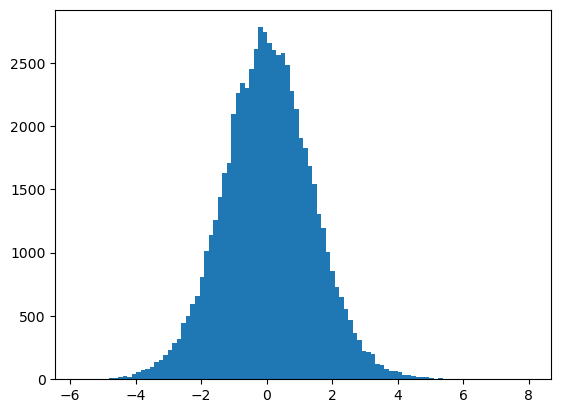

In [15]:
plt.hist(corrs.ravel() - M, bins = 100)